### Langchain version v.1


In [45]:
import langchain
langchain.__version__

'1.4.8'

In [5]:
#to check whether everything is working or not 
1+1

2

In [13]:
import os
from dotenv import load_dotenv
load_dotenv()

os.environ['OPEN-AI_API_KEY']=os.getenv("OPEN-AI_API_KEY")

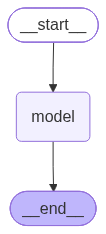

In [28]:
from langchain.agents import create_agent 
def get_weather(city:str)-> str:
    # """Get the weather for a city."""
    return f"The weather is {city} is Sunny."
agent = create_agent(
    model = "google_genai:gemini-3.8-flash",
    tools = [],
    system_prompt="You are helpful assistant"  

)
agent

#To check API Key Status

import os

api_key = os.getenv("OPENAI_API_KEY")

if api_key:
    print("OpenAI API Key: Found")
else:
    print("OpenAI API Key: Not Found")

#if you get an api key error
import os
from dotenv import load_dotenv

load_dotenv()

api_key = os.getenv("OPENAI_API_KEY")

if api_key:
    print("API Key successfully loaded!")
else:
    print("API Key not found!")

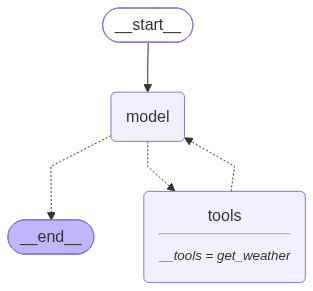

In [38]:
#now when we add the tools i.e. get weather the LLM will learn that it have to give weather for a city from the 
# quote Get the wather for a city 
from langchain.agents import create_agent 
def get_weather(city:str)-> str:
    """Get the weather for a city."""
    return f"The weather is {city} is Sunny."
agent = create_agent(
    model = "groq:openai/gpt-oss-120b",
    tools = [get_weather],
    system_prompt="You are helpful assistant"  

)
agent

In [41]:
###run the agent 
response=agent.invoke({"messages":[{"role":"user","content":"What is the weather like in Newyork?"}]})

In [ ]:
response['messages'][-1].content



'The current weather in New\u202fYork is **sunny**.'

In [47]:
#for having the last meassges of the last line then 
response['messages'][-1]

AIMessage(content='The current weather in New\u202fYork is **sunny**.', additional_kwargs={'reasoning_content': 'We need to respond to user query about weather in New York. The function returned "The weather is New York is Sunny." Probably we should present that nicely.'}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 172, 'total_tokens': 227, 'completion_time': 0.116277799, 'completion_tokens_details': {'reasoning_tokens': 33}, 'prompt_time': 0.007959788, 'prompt_tokens_details': None, 'queue_time': 0.211037347, 'total_time': 0.124237587}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_5a93aea882', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a279-ca3b-74d9-951e-254d2f60ca14-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 172, 'output_tokens': 55, 'total_tokens': 227, 'output_token_details': {'reasoning': 33}})

In [43]:
#If you want entire conversation 
response['messages']

[HumanMessage(content='What is the weather like in Newyork?', additional_kwargs={}, response_metadata={}, id='af40603b-fc8c-4b08-bf0f-afaad10292fb'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks "What is the weather like in Newyork?" We need to get weather. Use function get_weather with city "New York". The city likely "New York". Use function.', 'tool_calls': [{'id': 'fc_8cb66631-2115-438b-926d-e1176b77fecf', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 68, 'prompt_tokens': 138, 'total_tokens': 206, 'completion_time': 0.143814345, 'completion_tokens_details': {'reasoning_tokens': 40}, 'prompt_time': 0.042495243, 'prompt_tokens_details': None, 'queue_time': 0.476611407, 'total_time': 0.186309588}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_bb691ea66b', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'mo

In [ ]:
agent.invoke({"messages": "What is the weather in New York?"}) 

{'messages': [HumanMessage(content='What is the weather in New York?', additional_kwargs={}, response_metadata={}, id='396e1eb4-775e-4339-9c06-5890d2acf3d2'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks for weather in New York. We have a function get_weather that takes city. Use function.', 'tool_calls': [{'id': 'fc_09cf97d9-1b99-4aab-bd13-4be1832b27e8', 'function': {'arguments': '{"city":"New York"}', 'name': 'get_weather'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 50, 'prompt_tokens': 136, 'total_tokens': 186, 'completion_time': 0.10629192, 'completion_tokens_details': {'reasoning_tokens': 22}, 'prompt_time': 0.053804189, 'prompt_tokens_details': None, 'queue_time': 0.268396041, 'total_time': 0.160096109}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_4a7bb72c24', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1a27b-7717-727f-8